# Lesson 09b: Implementation of Allegro in e3nn

**What you will learn**

- How to implement the two-body scalar embedding (Bessel RBF $\times$ envelope
  $\times$ species one-hots), the initial equivariant features, and the Allegro
  layer (environment embedding $\to$ channel-wise tensor product $\to$ latent
  MLP $\to$ linear mixing).
- How to assemble pair-wise energies $E_{ij}$ into $E_\text{system}$ and get
  forces from autograd.
- How to verify energy invariance and force covariance under rotations,
  inversion, and translations in `float64` and check the smoothness of the model
  predictions at the cutoff.
- How to train Allegro (in `float32` on a GPU) on **rMD17 aspirin** dataset
  under the protocol of Lesson 08c. We plot and analyze the learning curves and
  the force parity plot.
- How to time a forward pass vs. atom count to connect strict locality to linear
  scaling.

**Prerequisites:**

- Lessons [03a](03a_tensor_products_theory.ipynb) and
  [03b](03b_tensor_products_e3nn.ipynb),
- Lessons [05a](05a_atomistic_graphs.ipynb) and
  [05b](05b_radial_basis_and_cutoffs.ipynb),
- Lessons [08a](08a_nequip_theory.ipynb), [08b](08b_nequip_implementation.ipynb)
  and [08c](08c_nequip_training.ipynb), and
- Lesson [09a](09a_allegro_theory.ipynb).

In [1]:
import sys; sys.path.insert(0, "..")

import time

import matplotlib.pyplot as plt
import numpy as np
import torch
from torch import nn
import torch.nn.functional as F
from e3nn import o3

from course_utils.data import load_rmd17, radius_graph
from course_utils.equivariance import model_equivariance_error
from course_utils.plotting import plot_training_curves

torch.manual_seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"
print(torch.__version__, "| device:", device)

2.7.1+cu126 | device: cuda


## Simplifications in Allegro's Implementation

In this lesson, we build a simple and small version of the **Allegro** model,
block by block, following the equations of Lesson 09a. Then, we verify its
symmetries and train it simultanelously on energies and forces. 

**Our model is educational** and faithful to the original implementation but we
have changed it to make it easier to understand and implement here. Explicitly:

| Paper | Here | Why |
|---|---|---|
| Per-species(-pair) $\sigma_{Z}, \mu_{Z}$, and $\sigma_{Z_iZ_j}$ | One global learnable scale $\sigma$ and shift $\mu$ | The species one-hots are kept (aspirin is H/C/O) but per-species output scales are a refinement we skip |
| All symmetrically valid tensor product paths (hyperparameter) | The output irreps are restricted to those of $\vec{Y}$: $0e, 1o, 2e$ | Fewer paths, same structure, and still exactly equivariant |
| Normalized residual update in the scalar latent space route | Plain residual $x^{ij,L} = x^{ij,L-1} + (\text{new})\cdot u(r_{ij})$ | Same idea but simpler |
| Large widths, $\ell_\text{max}=3$, deep latent MLPs | Latent width of 32, $C=8$ channels, $\ell_\text{max}=2$, 2 layers | Allows minutes-long training for the course |
| $E_{ij} = \mathrm{MLP}_\text{output}(x^{ij})$ | Additionally multiplied by the envelope, $u(r_{ij})$ | Guarantees $E_{ij}\to 0$ smoothly at the cutoff even with biased MLPs |
| Environment weights $w^{ik,L}$ | Additionally multiplied by the envelope, $u(r_{ik})$ | Neighbors must enter the sum smoothly as they cross the cutoff |

The last two rows are the only places we add something: without those envelope
factors, an MLP bias would make a neighbor appear/disappear discontinuously at
$r_c$ (the original Allegro achieves the same smoothness through its
normalization and envelope placement).

## Radial basis and cutoff envelope

As in Lesson 05b, distances are expanded in $N_\text{basis}$ Bessel functions,

$$B_n(r) = \sqrt{\frac{2}{r_c}}\, \frac{\sin(n \pi r / r_c)}{r}, \qquad n = 1, \dots, N_\text{basis},$$

and smoothness at the cutoff is enforced by the polynomial envelope introduced
with DimeNet and used by NequIP and Allegro, with $x = r/r_c$ and exponent $p$:

$$u(r) = 1 - \tfrac{(p+1)(p+2)}{2} x^{p} + p(p+2)\, x^{p+1} - \tfrac{p(p+1)}{2}\, x^{p+2}, \qquad u \equiv 0 \text{ for } r \ge r_c.$$

Note that $u$ has $p-1$ vanishing derivatives at $r = r_c$. Thus, basis
functions multiplied by it fade out smoothly. [Lesson
05b](05b_radial_basis_and_cutoffs.ipynb) plots both $B_n(r)$ and the product
$B_n(r)\,u(r)$ and shows numerically what a hard cutoff does to forces.
Therefore, we only restate the definitions here and move on.

In [2]:
# Lesson 08c's aspirin cutoff
r_cut = 5.0

class BesselBasis(nn.Module):
    """Bessel basis functions B_n(r)"""
    
    def __init__(self, r_cut, n_basis=8):
        super().__init__()
        self.r_cut, self.prefactor = r_cut, (2.0 / r_cut) ** 0.5
        self.register_buffer("n_pi", torch.arange(1, n_basis + 1) * torch.pi)

    def forward(self, r):
        # (E,) -> (E, n_basis)
        r = r.unsqueeze(-1)
        return self.prefactor * torch.sin(self.n_pi * r / self.r_cut) / r


def poly_envelope(r, r_cut, p=6):
    """Smooth cutoff u(r): u(0)=1, u and its first p-1 derivatives vanish at r_cut."""
    
    # The polynomial is defined in terms of x = r/r_cut, which is clamped to 1.0
    x = (r / r_cut).clamp(max=1.0)
    
    # The polynomial is constructed to satisfy the boundary conditions:
    # u(0) = 1, u(r_cut) = 0, and the first p-1 derivatives vanish at r_cut.
    u = (1.0 - (p + 1) * (p + 2) / 2 * x**p + p * (p + 2) * x**(p + 1)
         - p * (p + 1) / 2 * x**(p + 2))
    
    # The polynomial is multiplied by the indicator function (r < r_cut) to
    # ensure that u(r) = 0 for r >= r_cut.
    return u * (r < r_cut)


def scalar_mlp(dims):
    """Plain MLP with SiLU hidden activations which is only ever applied to invariants!"""
    
    layers = []
    for a, b in zip(dims[:-1], dims[1:]):
        layers += [nn.Linear(a, b), nn.SiLU()]
    
    # No activation on the output
    return nn.Sequential(*layers[:-1])

## Two-body embedding and helper for weighted spherical harmonics
 
Allegro embeds each atomic pair using its distance **and the identities of its
two atoms**:

$$x^{ij, L=0} = \mathrm{MLP}_\text{two-body}\big( B(r_{ij}) \Vert \mathbf{1}_{Z_i} \Vert \mathbf{1}_{Z_j} \big) \cdot u(r_{ij})$$

where $\mathbf{1}_Z$ is the one-hot encoding of the atomic species and $\Vert$
denotes concatenation. Aspirin has three species (H, C, O) and the one-hot
encodings allow the embedding to distinguish between different atomic pairs at
the same distance. For example, the embeddings of one-hot encodings of C–H pair
is different from that of a C–O pair at the same distance. As one-hot encodings
are invariant scalars, concatenating them cannot disturb the equivariance in the
model.

The initial features of the tensor latent space route are the weighted spherical
harmonics of the pair directions:

$$V^{ij,L=0}_{n,\ell,p} = w^{ij,L=0}_{n,\ell,p}\, \vec{Y}^{\,ij}_{\ell,p},$$

where

$$ w^{ij,L=0} = \mathrm{Linear}\big(x^{ij,L=0}\big).$$

The weighting operation (multiplying each irrep of $\vec{Y}$ by a per-channel
scalar) appears twice in Allegro: here, and again inside the environment
embedding of the layer. Therefore, we factor it out in a reusable function,
`weighted_sh(w, Y, irreps_Y)` below. This function takes `w` of shape 
`(E, c, n_irreps)`, which consists of one scalar per edge, channel and irrep,
together with `Y` of shape `(E, Y.dim)`, and returns `(E, c * Y.dim)`, laid out as the e3nn irreps 
`cx0e + cx1o + cx2e`, where $c$ is the number of channels. Note that 
multiplying an irrep by an invariant scalar, which commutes with $D^{(\ell)}(g)$,
keeps the results equivariant.

In [3]:
def weighted_sh(w, Y, irreps_Y):
    """w: (E, c, n_irreps) scalar weights;  Y: (E, Y.dim) spherical harmonics.
    Returns (E, c * Y.dim) with irreps [c x ir for ir in irreps_Y]"""
    
    # Create a list to hold the weighted spherical harmonics blocks and
    # initialize an index counter
    blocks, idx = [], 0
    
    # Loop over the irreps of Y and their corresponding weights
    for m, (_, ir) in enumerate(irreps_Y):
        
        # Compute the weighted spherical harmonics block for the current irrep
        # (E, c, 2l+1)
        blk = w[:, :, m : m + 1] * Y[:, None, idx : idx + ir.dim]
        
        # Reshape the block to (E, c * (2l+1)) and append it to the list of
        # blocks
        blocks.append(blk.reshape(len(Y), blk.shape[1] * blk.shape[2]))
        
        # Update the index counter
        idx += ir.dim
    
    # Concatenate all the blocks along the last dimension to form the final
    # output
    return torch.cat(blocks, dim=-1)


The $\mathrm{MLP}_\text{two-body}$ (and the $\mathrm{Linear}$ layer) that
produces the weights, $w^{ij,L=0}$, are assembled directly inside `AllegroModel`
later in the text when we implement the full Allegro model.

## Channel-wise tensor product

Here, we need to implement a layer that couples the tensor latent space track
with its environment through a tensor product that is **weight-free and
channel-wise**: channel $c$ of the first input only ever meets channel $c$ of
the second one (e3nn's `"uuu"` instruction mode). We also keep only those output
irreps that $V$ already carries (i.e., $0e$, $1o$, $2e$) while discarding any
path the selection rule permits but this architecture never uses.

The `channelwise_tp(irreps_V, irreps_env, allowed)` function below enumerates
the surviving paths and returns the configured `o3.TensorProduct`. The Allegro
layer in the next section calls it exactly once, in its constructor.

In [4]:
def channelwise_tp(irreps_V, irreps_env, allowed):
    """Weight-free channel-wise ("uuu") tensor product with all allowed paths
    built in Lesson 09a."""
    
    # Convert the allowed irreps to a set for faster lookup
    allowed = {o3.Irrep(ir) for ir in allowed}
    
    # Initialize the output irreps and instructions for the tensor product
    irreps_out, instructions = [], []
    for i1, (mul, ir1) in enumerate(irreps_V):
        for i2, (_, ir2) in enumerate(irreps_env):
            
            # Selection rule
            for ir_out in ir1 * ir2:
                
                # Check if the output irrep is in the allowed set
                if ir_out in allowed:
                    
                    # Add the instruction for this allowed tensor product path
                    instructions.append((i1, i2, len(irreps_out), "uuu", False))
                    
                    # Record the output irrep for this tensor product path
                    irreps_out.append((mul, ir_out))
    
    # Return the tensor product object with the computed output irreps and
    # instructions
    return o3.TensorProduct(irreps_V, irreps_env, o3.Irreps(irreps_out), instructions,
                            internal_weights=False, shared_weights=False)


## The Allegro layer

The Allegro layer implements the four components from Lesson 09a:

1. **Environment weights**: $w^{ik,L} = \mathrm{Linear}(x^{ik,L-1}) \cdot
   u(r_{ik})$. Our extra envelope factor, $u(r_{ik})$ makes extrnal atoms enter
   the atomic neighborhood smoothly.

2. **Embedded environment + tensor product**: $\;V^{ij,L}_\text{paths} =
   V^{ij,L-1} \otimes \Big(\sum_{k \in \mathcal{N}(i)} w^{ik,L}
   \vec{Y}^{ik}\Big)$. The sum over $k$ is a scatter-add over all edges with
   center $i$, then divided by $\sqrt{\langle |\mathcal{N}(i)| \rangle}$.

3. **Latent MLP + residual**: the $0e$ outputs of the tensor product re-enter
   the scalar latent space track.
   
4. **Linear mixing**: The `o3.Linear` layer recombines all paths carrying the same irrep
   into $c$ channels.

In [5]:
class AllegroLayer(nn.Module):
    """Allegro layer as described in the paper, with some simplifications for
    the course."""
    
    def __init__(self, irreps_V, irreps_Y, latent_dim, avg_n_neighbors):
        super().__init__()
        
        # Convert the input irreps to e3nn Irreps objects and store them
        irreps_V, self.irreps_Y = o3.Irreps(irreps_V), o3.Irreps(irreps_Y)
        
        # Store the number of channels and the average number of neighbors for normalization
        self.C, self.avg_n = irreps_V[0].mul, avg_n_neighbors
        
        # (1) Environment embedding weights
        self.env_embed = nn.Linear(latent_dim, self.C * len(self.irreps_Y))
        irreps_env = o3.Irreps([(self.C, ir) for _, ir in self.irreps_Y])
        
        # (2) Channel-wise tensor product
        self.tp = channelwise_tp(irreps_V, irreps_env, [ir for _, ir in irreps_V])
        
        # Scalar slices for locating the 0e outputs of the tensor product
        self.scalar_slices, idx = [], 0
        for mul, ir in self.tp.irreps_out:
            if ir == o3.Irrep("0e"):
                self.scalar_slices.append((idx, idx + mul * ir.dim))
            idx += mul * ir.dim
        n_scalars = sum(b - a for a, b in self.scalar_slices)
        
        # (3) Latent MLP
        self.latent_mlp = scalar_mlp([latent_dim + n_scalars, latent_dim, latent_dim])
        
        # (4) Linear mixing of paths
        self.linear = o3.Linear(self.tp.irreps_out, irreps_V)

    def forward(self, x, V, Y, u, edge_center, n_atoms):
        # w^{ik,L}: (E, C, n_irreps_Y), smooth at the cutoff
        w = self.env_embed(x).reshape(len(x), self.C, len(self.irreps_Y)) * u[:, None, None]
        
        # Embedded environment: scatter-add over edges with center i; inner sum
        env_edge = weighted_sh(w, Y, self.irreps_Y)
        env = torch.zeros(n_atoms, env_edge.shape[-1], device=Y.device, dtype=Y.dtype)
        env.index_add_(0, edge_center, env_edge)
        
        # Internal normalization
        env = env / self.avg_n ** 0.5
        
        # Tensor product with the environment
        tp_out = self.tp(V, env[edge_center])
        
        # Extract scalar outputs from the tensor product and update the latent features
        scal = torch.cat([tp_out[:, a:b] for a, b in self.scalar_slices], dim=-1)
        
        # Residual update of the latent features using the latent MLP and the scalar outputs
        x = x + self.latent_mlp(torch.cat([x, scal], dim=-1)) * u[:, None]
        
        # Linear mixing of the tensor product outputs to produce the final output
        V = self.linear(tp_out)
        return x, V

## The full model

In our final assembly of the model, we use the envelope $u(r_{ij})$ to ensure
that $E_{ij} \to 0$ smoothly at the cutoff, even if the MLP output is biased

$$E_{ij} = \mathrm{MLP}_\text{output}\big(x^{ij,L=N_\text{layer}}\big) \cdot u(r_{ij}).$$

We also use a single global learnable scale $\sigma$ and shift $\mu$, rather
than the original Allegro's per-species pair:

$$E_i = \sum_{j \in \mathcal{N}(i)} E_{ij}\qquad\qquad E_\text{system} = \sum_i^N \sigma E_i + \mu$$

Following the [Allegro manuscript](https://doi.org/10.1038/s41467-022-29939-5),
we initialize $\sigma$ to the root-mean-square of the training force components
and subtract the training set's mean energy *per atom* from the targets (Lesson
08c's recipe), leaving $\mu$ free to absorb the remainder. Note that in our
course, we adopt the following edge convention: `edge_index[0]` =
receiver/center $i$, `edge_index[1]` = sender/neighbor $j$, which are used in
the interatomic direction vector as, $\vec{r}_{ij} = \vec{r}_j - \vec{r}_i$.

In [6]:
class AllegroModel(nn.Module):
    """Allegro model as described in the paper, with some simplifications for
    the course."""
    
    def __init__(self, r_cut=5.0, n_basis=8, latent_dim=32, n_channels=8, l_max=2,
                 n_layers=2, n_species=1, avg_n_neighbors=4.0,
                 energy_shift=0.0, energy_scale=1.0):
        super().__init__()
        
        # Store the cutoff radius and number of species for later use
        self.r_cut, self.n_species = r_cut, n_species
        
        # Define the irreducible representations (irreps) for the spherical harmonics up to l_max
        # 1x0e+1x1o+1x2e
        self.irreps_Y = o3.Irreps.spherical_harmonics(l_max)
        
        # Define the irreducible representations for the latent features V,
        # which are constructed by repeating each irrep in irreps_Y n_channels
        # times
        irreps_V = o3.Irreps([(n_channels, ir) for _, ir in self.irreps_Y])
        self.C = n_channels
        
        # Define the Bessel basis functions for the radial part of the model
        self.basis = BesselBasis(r_cut, n_basis)
        
        # B(r) concatenated with the one-hots of BOTH atoms of the pair
        self.two_body_mlp = scalar_mlp([n_basis + 2 * n_species, latent_dim, latent_dim])
        
        # Define the initial embedding layer that maps the latent features to the
        # appropriate number of channels for the tensor product with the spherical harmonics
        self.embed0 = nn.Linear(latent_dim, n_channels * len(self.irreps_Y))
        
        # Define the Allegro layers that perform the message passing and update
        # the latent features and irreps
        self.layers = nn.ModuleList(
            [AllegroLayer(irreps_V, self.irreps_Y, latent_dim, avg_n_neighbors)
             for _ in range(n_layers)])
        
        # Define the readout layer that maps the final latent features to a
        # scalar energy contribution for each edge
        self.readout = scalar_mlp([latent_dim, latent_dim, 1])
        
        # Define the learnable shift and scale parameters for the final energy output
        self.shift = nn.Parameter(torch.tensor(float(energy_shift)))
        self.scale = nn.Parameter(torch.tensor(float(energy_scale)))

    def forward(self, pos, edge_index, species=None, batch=None, n_graphs=1):
        # Ensure that the batch and species tensors are provided; if not, create default tensors
        if batch is None:
            batch = torch.zeros(len(pos), dtype=torch.long, device=pos.device)
        if species is None:
            species = torch.zeros(len(pos), dtype=torch.long, device=pos.device)
        
        # Extract the sender and receiver indices from the edge_index tensor
        i, j = edge_index[0], edge_index[1]
        
        # r_ij = r_j - r_i
        r_vec = pos[j] - pos[i]
        
        # Compute the Euclidean norm of the interatomic vectors to obtain the
        # distances
        r = r_vec.norm(dim=-1)
        
        # Compute the smooth cutoff envelope function u(r) to ensure that the
        # energy contributions go to zero smoothly at the cutoff distance
        u = poly_envelope(r, self.r_cut)
        
        # Compute the spherical harmonics Y for the interatomic vectors r_vec,
        # normalized and with the specified irreps
        Y = o3.spherical_harmonics(self.irreps_Y, r_vec, normalize=True,
                                   normalization="component")
        
        # Compute the one-hot encoding of the species for both atoms in the pair (1_Z)
        hot = F.one_hot(species, self.n_species).to(pos.dtype)
        
        # Compute the initial latent features x for each edge by concatenating the
        # Bessel basis functions, the one-hot encodings of the species, and
        # applying the two-body MLP, followed by multiplication with the smooth
        # cutoff envelope u(r)
        x = self.two_body_mlp(
            torch.cat([self.basis(r), hot[i], hot[j]], dim=-1)) * u[:, None]
        
        # Apply the embedding layer to the initial latent features
        w0 = self.embed0(x).reshape(len(x), self.C, len(self.irreps_Y))
        
        # Compute the initial irreps V by applying the weighted spherical harmonics
        V = weighted_sh(w0, Y, self.irreps_Y)
        
        # Iteratively apply each Allegro layer to update the latent features x and
        # irreps V based on the interatomic distances, spherical harmonics, and
        # smooth cutoff envelope
        for layer in self.layers:
            x, V = layer(x, V, Y, u, i, len(pos))
            
        # Compute the energy contributions E_ij for each edge by applying the
        # readout MLP to the final latent features x and multiplying by the
        # smooth cutoff envelope u(r)
        E_ij = self.readout(x).squeeze(-1) * u
        
        # Aggregate the energy contributions E_ij for each atom i by summing
        # over the edges that have i as the receiver, and then aggregate the
        # atomic energies to obtain the total energy for each graph in the
        # batch, applying the learnable scale and shift parameters to the final
        # energy output
        E_i = torch.zeros(len(pos), device=pos.device, dtype=pos.dtype)
        E_i.index_add_(0, i, E_ij)
        E = torch.zeros(n_graphs, device=pos.device, dtype=pos.dtype)
        E.index_add_(0, batch, self.scale * E_i + self.shift)
        return E

## Verifying the symmetries

The model must satisfy, for every rotation and reflection $g \in O(3)$ as well
as translation $\vec{t}$, the energy invariance:

$$E(g\,\vec{r}_1 + \vec{t}, \dots) = E(\vec{r}_1, \dots)$$

and the force equivariance (covariance) relations,

$$\vec{F}_i(g\,\vec{r} + \vec{t}) = g\, \vec{F}_i(\vec{r}).$$

We test the validity of these relations in float64, using random group elements
including inversion ($g = -R$) and translations, so that any genuine symmetry
breaking operation can stand out from round-off noise ($\sim 10^{-15}$). Note
that the edge list is reused without any change: as distances are
E(3)-invariant, the atomic graph itself remains unchanged.

Let's start by implementing a helper function that calculates the energy and
forces for a given model and atomic configuration. 

In [7]:
def forces(model, pos, edge_index, species=None, batch=None, n_graphs=1,
           create_graph=False):
    """F = -dE/dr via autograd"""
    
    # Ensure that the position tensor requires gradients for autograd to compute
    # forces 
    pos = pos.requires_grad_(True)
    
    # Compute the energy E using the model and the provided positions, edge
    # indices, species, batch, and number of graphs. 
    E = model(pos, edge_index, species, batch, n_graphs)
    
    # Compute the gradient of the energy with respect to the positions using
    # autograd. The create_graph argument allows for higher-order derivatives
    # to be computed if needed. The allow_unused argument is set to True to
    # handle cases where there are no edges, which would result in no dependence
    # of the energy on the positions.
    (grad,) = torch.autograd.grad(E.sum(), pos, create_graph=create_graph,
                                  allow_unused=True)
    
    # If the gradient is None (e.g., when there are no edges), create a zero tensor
    # with the same shape as pos to represent the forces. Otherwise, return the
    # negative of the computed gradient as the forces.
    grad = torch.zeros_like(pos) if grad is None else grad
    return E, -grad

We can now proceed to initialize the Allegro model and verify its symmetries on
a random configuration

In [8]:
# Set the random seed for reproducibility
torch.manual_seed(0)

# Build a float64 copy of the model for the symmetry checks
torch.set_default_dtype(torch.float64)
model64 = AllegroModel(r_cut=r_cut, n_species=3)

# Restore the default dtype to float32 for subsequent computations 
torch.set_default_dtype(torch.float32)
print(f"parameters: {sum(p.numel() for p in model64.parameters()):,}")

# Create a random test configuration with 12 atoms in 3D space
pos_test = torch.randn(12, 3, dtype=torch.float64) * 2.0

# Create a random species tensor for the test configuration, representing a
# mixed cluster of H, C, and O atoms
spec_test = torch.randint(0, 3, (12,))

# Compute the edge indices for the test configuration using a radius graph
ei_test = radius_graph(pos_test, r_cut)

# Compute the energy and forces for the test configuration using the Allegro model
E, F_test = forces(model64, pos_test.clone(), ei_test, spec_test)
print(f"test config: {ei_test.shape[1]} edges | E = {E.item():+.4f} | F shape {tuple(F_test.shape)}")

parameters: 12,171
test config: 88 edges | E = +3.5491 | F shape (12, 3)


First, we use the `model_equivariance_error` helper function from Lesson 08c to verify
the energy invariance

In [9]:
# Energy invariance: E is a single 0e output
err_E = model_equivariance_error(
    lambda p, edge_index=None: model64(p, edge_index, spec_test).unsqueeze(-1),
    pos_test,
    irreps_out="0e",
    n_trials=10,
    parity=True,
    translation=True,
    edge_index=ei_test,
)
print(f"Energy invariance:  max |E(g r + t) - E(r)| = {err_E:.3e}")
assert err_E < 1e-9

Energy invariance:  max |E(g r + t) - E(r)| = 8.882e-16


Next, we check the force equivariance under random O(3) elements (half of them
improper) and translations, directly

In [10]:
# Calculate the forces for the original test configuration
_, F0 = forces(model64, pos_test.clone(), ei_test, spec_test)

# Set the initial maximum error for force covariance to zero
err_F = 0.0

# Run 10 trials to test force covariance
for _ in range(10):
    # Generate a random O(3) transformation matrix g
    g = o3.rand_matrix(dtype=torch.float64)
    
    # Randomly decide whether to use an improper transformation
    # (inversion/parity) by negating g with 50% probability
    if torch.rand(()) < 0.5:
        g = -g
    
    # Generate a random translation vector t
    t = torch.randn(3, dtype=torch.float64)
    
    # Compute the forces for the transformed configuration and compare them to
    # the expected forces
    _, F_g = forces(model64, (pos_test @ g.T + t), ei_test, spec_test)
    
    # Update the maximum error for force covariance based on the difference
    # between the computed forces and the expected forces after applying the
    # O(3)
    err_F = max(err_F, (F_g - F0 @ g.T).abs().max().item())

# Print the maximum error for force covariance and assert that it is below the
# threshold of 1e-9 to ensure that the model satisfies the force covariance
# property
print(f"Force covariance:   max |F(g r + t) - g F(r)| = {err_F:.3e}")
assert err_F < 1e-9

Force covariance:   max |F(g r + t) - g F(r)| = 1.582e-15


## Dataset and training protocol

We train on **rMD17 aspirin** (Lesson 07c / `course_utils.data.load_rmd17`)
under exactly the protocol of Lesson 08c: the official split 01, 150 training
and 50 validation frames of the 21-atom molecule (H/C/O), using a cutoff value
of $r_c = 5$ Å, mini-batches of 25 frames, and the training set's mean energy
per atom subtracted from the targets. 

Holding the protocol fixed is important for our benchmark here: it enables a
direct comparison between Allegro's validation force MAE and the previously
reported 85.28 meV/Å value that NequIP reached in 08c, based on the same set of
atomic frames and the same metric.

It is also important to note that this dataset offers a realistic test of the
tensorial latent space track in Allegro in a way that the LJ argon data was
never able to provide. Argon's energy is a sum of *pair* terms depending only on
distance Thus, invariant features nearly suffice (that is why Lessons 07a–08b
use it as a cheap shared control). Aspirin's DFT surface has bond angles,
dihedrals, conjugation and an aromatic ring. As such, the $\ell \ge 1$ features
become essential to capture the physics of the system.

Here, we adopt the per-atom-normalized joint loss of the 
[Allegro manuscript](https://doi.org/10.1038/s41467-022-29939-5)

$$\mathcal{L} = \frac{\lambda_E}{B} \sum_b^B \left( \frac{\hat{E}_b - E_b}{N} \right)^2 + \frac{\lambda_F}{3 B N} \sum_{i=1}^{BN} \sum_{\alpha=1}^{3} \left\| -\frac{\partial \hat{E}}{\partial r_{i,\alpha}} - F_{i,\alpha} \right\|^2$$

where $\lambda_E = \lambda_F = 1$, $B$ is the batch size (batch of structures of
$N$ atoms each), and $\alpha$ denotes the Cartesian component. We should note
that **each model is trained with its own paper's loss**. As such, you should
see this experiment as a comparison of two published recipes on one dataset, not
a controlled single-variable ablation study. The Allegro loss weights the energy
term by $1/N^2$ while the NequIP's loss (Lesson 08c) does not. Similar to the
[Allegro manuscript](https://doi.org/10.1038/s41467-022-29939-5), we use Adam
with a cosine-annealed learning rate and run the training in float32 on a GPU.

Let's start by loading the dataset and printing some statistics about it.

In [11]:
# Lesson 08c's data protocol: official rMD17 split 01, r_cut = 5 Å, per-atom
# mean shift
train_frames, val_frames, z_asp = load_rmd17("aspirin", n_train=150, n_val=50,
                                             cache_dir="artifacts")

# Map the atomic numbers in z_asp to a contiguous range of species indices starting from 0. 
# {1:0, 6:1, 8:2}
species_map = {int(Z): s for s, Z in enumerate(torch.unique(z_asp).tolist())}
species_asp = torch.tensor([species_map[int(Z)] for Z in z_asp])
N_ATOMS, N_SPECIES = len(z_asp), len(species_map)

# Statistics for normalization
# mean E/atom
eps_bar = float(np.mean([f["energy"] for f in train_frames])) / N_ATOMS
avg_n = float(np.mean([radius_graph(f["pos"], r_cut).shape[1] / N_ATOMS
                       for f in train_frames]))

# Compute the root mean square (RMS) of the forces across all training frames
F_scale = torch.cat([f["forces"].reshape(-1) for f in train_frames]).pow(2).mean().sqrt()

# Print out the dataset statistics
print(f"aspirin: {N_ATOMS} atoms (H/C/O) | {len(train_frames)} train / {len(val_frames)} val")
print(f"avg neighbors: {avg_n:.1f} | E/atom mean: {eps_bar:.4f} eV | F rms: {F_scale*1e3:.1f} meV/A")

aspirin: 21 atoms (H/C/O) | 150 train / 50 val
avg neighbors: 14.4 | E/atom mean: -838.9382 eV | F rms: 1273.2 meV/A


Next, we implement helper functions for data pre-processing and energy/force
evaluation.

In [12]:
def prep(frames, dtype=torch.float32):
    """Precompute float32 graphs once. The energies carry the per-atom mean shift."""
    
    # Returns a list of tuples, each containing the position, edge indices,
    # energy, and forces for each frame.
    return [(f["pos"].to(dtype), radius_graph(f["pos"].to(dtype), r_cut),
             torch.tensor(float(f["energy"]) - len(f["pos"]) * eps_bar, dtype=dtype),
             f["forces"].to(dtype)) for f in frames]

# Process the training and validation frames to float32 graphs, applying the
# per-atom mean shift to the energies.
train_data, val_data = prep(train_frames), prep(val_frames)

def collate(items):
    """Merge frames into one block-diagonal batch graph."""
    
    # Concatenate the positions of all frames into a single tensor
    pos = torch.cat([p for p, _, _, _ in items])
    
    # Create containers for edge indices, batch indices, and an offset for the
    # edge indices
    eis, batch, off = [], [], 0
    for k, (p, e, _, _) in enumerate(items):
        
        # Append the edge indices for the current frame, adjusted by the offset,
        # to the list of edge indices.
        eis.append(e + off); batch += [k] * len(p); off += len(p)
    
    # Create a tensor for the species, repeating the species_asp tensor for each
    # frame
    spec = species_asp.repeat(len(items))
    
    # Return the concatenated positions, edge indices, species tensor, batch tensor,
    # energies, and forces for the entire batch of frames.
    return (pos, torch.cat(eis, dim=1), spec, torch.tensor(batch),
            torch.stack([E for _, _, E, _ in items]), torch.cat([f for _, _, _, f in items]))

# Create a single batch from the validation data by collating the individual
# frames
val_batch = [t.to(device) for t in collate(val_data)]

def evaluate(model):
    """Evaluate the model on the validation batch and return the mean absolute
    errors for energy and forces."""
    
    # Extract the positions, edge indices, species, batch indices, reference energies,
    # and reference forces from the validation batch.
    pos, ei, spec, batch, E_ref, F_ref = val_batch
    
    # Compute the predicted energies and forces using the model and the
    # validation batch data.
    E_hat, F_hat = forces(model, pos.clone(), ei, spec, batch, len(val_data))
    return ((E_hat - E_ref).abs().mean().item() / N_ATOMS * 1e3,   # meV / atom
            (F_hat - F_ref).abs().mean().item() * 1e3)             # meV / A

The helper functions are in place. Nest, we setup the necessary ingredients for
the training loop (e.g., model instance, optimizer, scheduler etc.) and run the
training for 600 epochs:

In [13]:
# Set the random seed for reproducibility
torch.manual_seed(0)

# Instantiate the Allegro model
model = AllegroModel(r_cut=r_cut, n_species=N_SPECIES, avg_n_neighbors=avg_n,
                     energy_shift=0.0, energy_scale=float(F_scale)).to(device)

# Print the total number of parameters in the model
print(f"parameters: {sum(p.numel() for p in model.parameters()):,} (float32, {device})")

# Lesson 08c's optimizer settings, so the two (NeqIP and Allegro) runs differ
# only in the architecture
n_epochs, batch_size = 600, 25
opt = torch.optim.Adam(model.parameters(), lr=1e-2)
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=n_epochs)

parameters: 12,171 (float32, cuda)


In [14]:
# Container to store the training history
history = {"train loss": [], "val E MAE [meV/atom]": [], "val F MAE [meV/A]": []}

# Create batches of training data by splitting the train_data into chunks of
# size batch_size
batches = [[train_data[k] for k in range(s, min(s + batch_size, len(train_data)))]
           for s in range(0, len(train_data), batch_size)]

# Start the training loop and record the start time
t0 = time.time()
for epoch in range(n_epochs):
    losses = []
    for items in batches:
        pos, ei, spec, batch, E_ref, F_ref = [t.to(device) for t in collate(items)]
        E_hat, F_hat = forces(model, pos, ei, spec, batch, len(items), create_graph=True)
        loss = (((E_hat - E_ref) / N_ATOMS).pow(2).mean()        # lambda_E = 1
                + (F_hat - F_ref).pow(2).mean())                 # lambda_F = 1
        opt.zero_grad(); loss.backward(); opt.step()
        losses.append(loss.item())
    sched.step()
    e_mae, f_mae = evaluate(model)
    history["train loss"].append(np.mean(losses))
    history["val E MAE [meV/atom]"].append(e_mae)
    history["val F MAE [meV/A]"].append(f_mae)
    if epoch % 100 == 0 or epoch == n_epochs - 1:
        print(f"epoch {epoch:3d} | loss {np.mean(losses):.3e} | "
              f"val E MAE {e_mae:7.3f} meV/atom | val F MAE {f_mae:7.2f} meV/A")
print(f"training time: {time.time() - t0:.0f} s on {device}")

epoch   0 | loss 1.970e+00 | val E MAE 251.255 meV/atom | val F MAE  930.78 meV/A
epoch 100 | loss 2.044e-02 | val E MAE  23.668 meV/atom | val F MAE  114.22 meV/A
epoch 200 | loss 9.073e-03 | val E MAE  13.155 meV/atom | val F MAE   77.77 meV/A
epoch 300 | loss 5.972e-03 | val E MAE   6.057 meV/atom | val F MAE   70.27 meV/A
epoch 400 | loss 6.713e-03 | val E MAE  15.144 meV/atom | val F MAE   77.68 meV/A
epoch 500 | loss 4.145e-03 | val E MAE   1.537 meV/atom | val F MAE   62.79 meV/A
epoch 599 | loss 3.961e-03 | val E MAE   1.510 meV/atom | val F MAE   62.39 meV/A
training time: 204 s on cuda


We can use the stored training history to plot the learning curves and analyze
the results.

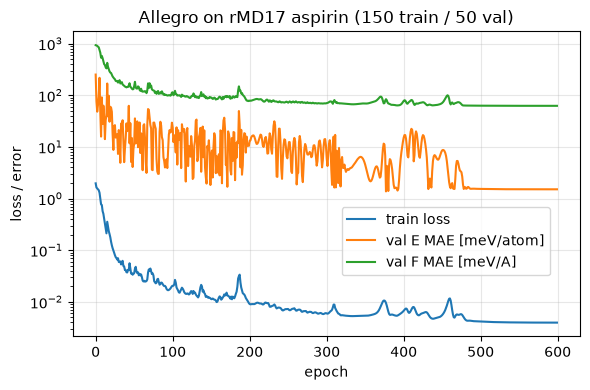

In [15]:
# Plot the training curves for the loss and validation metrics
ax = plot_training_curves(history)
ax.set_title("Allegro on rMD17 aspirin (150 train / 50 val)")
ax.legend(loc=(.53, 0.2))
ax.figure.tight_layout()

Let's evaluate the model on the validation set and compare the results to the
reference values in a parity plot

final validation:  E MAE = 1.510 meV/atom | F MAE = 62.39 meV/A
NequIP on the same frames (Lesson 08c): E MAE = 1.51 meV/atom | F MAE = 85.28 meV/A


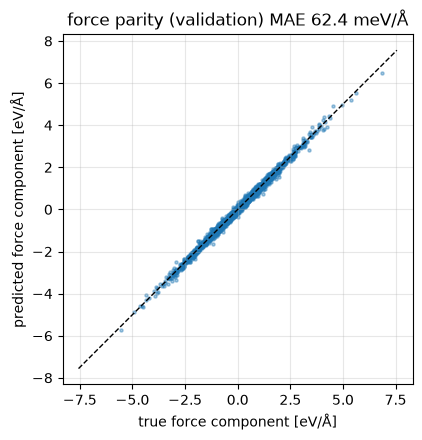

In [16]:
# Evaluate the final model on the validation batch and print the mean absolute
# errors for energy and forces
pos, ei, spec, batch, E_ref, F_ref = val_batch
E_hat, F_hat = forces(model, pos.clone(), ei, spec, batch, len(val_data))
e_mae, f_mae = evaluate(model)
print(f"final validation:  E MAE = {e_mae:.3f} meV/atom | F MAE = {f_mae:.2f} meV/A")
print(f"NequIP on the same frames (Lesson 08c): E MAE = 1.51 meV/atom | F MAE = 85.28 meV/A")

# Plot the parity plot for the predicted vs. reference force components on the
# validation set
fig, ax = plt.subplots(figsize=(4.5, 4.5))
F_t, F_p = F_ref.cpu().numpy().ravel(), F_hat.detach().cpu().numpy().ravel()
ax.scatter(F_t, F_p, s=5, alpha=0.4)
lim = np.abs(F_t).max() * 1.1
ax.plot([-lim, lim], [-lim, lim], "k--", lw=1)
ax.set_xlabel(r"true force component [eV/$\mathrm{\AA}$]")
ax.set_ylabel(r"predicted force component [eV/$\mathrm{\AA}$]")
ax.set_title(rf"force parity (validation) MAE {f_mae:.1f} meV/$\mathrm{{\AA}}$")
ax.set_aspect("equal")
ax.grid(alpha=0.3)
fig.tight_layout()

## Sanity checks after training

The training must not (and cannot) break the symmetries of the model. To verify
this, we will check the energy invariance and force equivariance under random rotations, reflections,
and translations as shown below

In [17]:
# Get the positions, edge indices, and species for the first validation frame
# and move them to the specified device (CPU or GPU) for evaluation.
pos32 = val_data[0][0].to(device)
ei32 = val_data[0][1].to(device)
spec32 = species_asp.to(device)

# Compute the energy and forces for the original configuration using the trained
# model
E0 = model(pos32, ei32, spec32)
_, F0 = forces(model, pos32.clone(), ei32, spec32)

# Check the energy invariance and force equivariance under random rotations,
# reflections, and translations. The errors are computed in float32 precision.
err_E32, err_F32 = 0.0, 0.0
for _ in range(10):
    
    # Generate a random O(3) transformation matrix g (rotation or reflection)
    g = o3.rand_matrix(dtype=torch.float32, device=device)
    
    # Randomly decide whether to use an improper transformation
    # (inversion/parity)
    if torch.rand(()) < 0.5:
        g = -g
    
    # Generate a random translation vector t
    t = torch.randn(3, device=device)
    
    # Compute the energy and forces for the transformed configuration and
    # compare them to the original energy and forces to check for invariance and
    # equivariance
    E_g = model(pos32 @ g.T + t, ei32, spec32)
    _, F_g = forces(model, (pos32 @ g.T + t), ei32, spec32)
    err_E32 = max(err_E32, (E_g - E0).abs().max().item())
    err_F32 = max(err_F32, (F_g - F0 @ g.T).abs().max().item())
print(f"trained model, float32: energy error {err_E32:.2e} eV, force error {err_F32:.2e} eV/A")

# float32 round-off floor, not symmetry breaking
assert err_E32 < 1e-4 and err_F32 < 1e-4      

trained model, float32: energy error 3.55e-06 eV, force error 2.03e-05 eV/A


In order to verify the smoothness of the energy and atomic forces, predicted by
our trained model, we scan an isolated **C–C pair** through $r = r_c$ and check
the smoothness of the energy and force predictions. Because every pair quantity
in the model carries the envelope $u(r)$, the interaction energy and force must
go to zero smoothly. Beyond $r_c$ the model returns exactly $2\mu$ (twice the
isolated-atom shifts). A discontinuity at $r_c$ would make MD simulation
unstable (Lesson 05b). 

We batch all scan points as independent 2-atom graphs and keep the $>r_c$ edges
in the graph on purpose to demonstrate that their contribution must vanish
identically. Note that this experiment also focuses on the **extrapolation**
capabilities of the trained model as it only ever saw whole aspirin molecules,
but never an isolated pair. We also point out that only the behaviour at $r_c$
is the claim here, not the shape of the curve.

beyond cutoff: |E - 2 mu| = 0.00e+00 eV (exactly the shift)


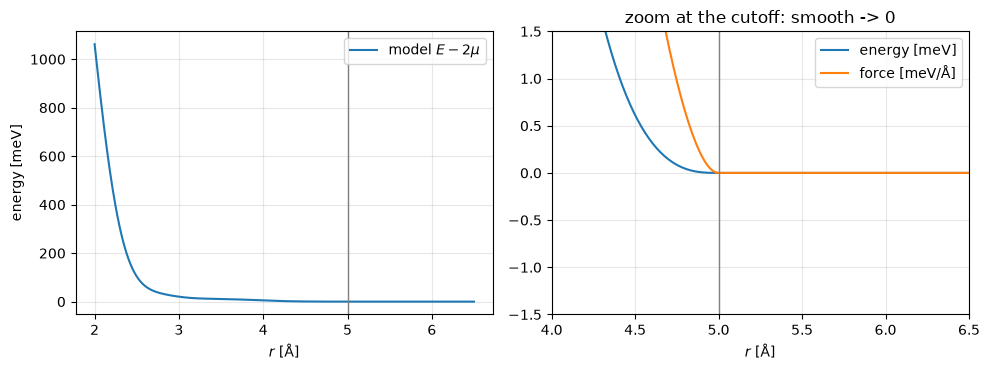

In [18]:
# Create a linearly spaced tensor of distances (r_scan) from 2.0 to 6.5 Å with
# 400 points
n_scan = 400
r_scan = torch.linspace(2.0, 6.5, n_scan, device=device)

# Create a tensor (pos_d) to hold the positions of the atoms in the dimer
# configuration
pos_d = torch.zeros(2 * n_scan, 3, device=device)

# Pair k: atoms 2k, 2k+1
pos_d[1::2, 0] = r_scan

# Create a tensor (k2) to hold the indices of the first atom in each pair
k2 = torch.arange(n_scan, device=device) * 2
ei_d = torch.cat([torch.stack([k2, k2 + 1]), torch.stack([k2 + 1, k2])], dim=1)

# Create a tensor (batch_d) to hold the batch indices for each atom in the dimer
batch_d = torch.arange(n_scan, device=device).repeat_interleave(2)

# C-C pair
spec_d = torch.full((2 * n_scan,), species_map[6], device=device)

# Compute the energy and forces for the dimer configuration using the trained
# model
E_d, F_d = forces(model, pos_d, ei_d, spec_d, batch_d, n_scan)

# Remove twice the isolated-atom shifts
E_int = (E_d - 2 * model.shift).detach().cpu()

# Force on the far atom
F_x = F_d[1::2, 0].detach().cpu()

# Convert the distances (r_scan) to a NumPy array for plotting
r_np = r_scan.cpu().numpy()

# Create a figure with two subplots to visualize the energy and force as a
# function of the interatomic distance, with a focus on the behavior near the
# cutoff distance.
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
axes[0].plot(r_np, E_int * 1e3, label=r"model $E - 2\mu$")
axes[0].set_ylabel("energy [meV]")
axes[0].legend()
axes[1].plot(r_np, E_int * 1e3, label="energy [meV]")
axes[1].plot(r_np, F_x * 1e3, label=r"force [meV/$\mathrm{\AA}$]")
axes[1].set_xlim(r_cut - 1.0, 6.5)
axes[1].set_ylim(-1.5, 1.5)
axes[1].legend()
axes[1].set_title("zoom at the cutoff: smooth -> 0")
for ax in axes:
    ax.axvline(r_cut, color="gray", lw=1)
    ax.set_xlabel(r"$r$ [$\mathrm{\AA}$]")
    ax.grid(alpha=0.3)
fig.tight_layout()
beyond = (E_d[r_scan > r_cut] - 2 * model.shift).abs().max().item()
print(f"beyond cutoff: |E - 2 mu| = {beyond:.2e} eV (exactly the shift)")

The right panel shows that the energy and force vanish smoothly at $r_c$, and
beyond it the prediction is exactly twice the isolated-atom constant, $2\mu$.
The left panel demonstrates the extrapolation: While the shape of the energy
conveys nothing important, its behavior at the cutoff radius does.

## Timing: forward pass vs. atom count

Allegro's strict locality makes its cost proportional to the number of pairs. We
time the energy and force calculations on random configurations at roughly the
density of solid aspirin ($\rho \approx 0.1$ atoms/Å$^3$), species drawn at
random from H/C/O. The factor we monitor is the **cost per edge**, which is
constant to a few percent across the sweep which conforms to the
$\mathcal{O}(N)$ claim of Allegro. The total cost grows slightly faster than
$N$, which is a property of the test we are running rather than of the model:
our boxes are finite and non-periodic. Therefore, atoms near the box faces have
truncated shells. In our tests, the pairs per atom climb from $\approx 40$ at $N
= 1024$ toward the bulk value $\tfrac{4}{3}\pi r_c^3 \rho \approx 52$ ($\approx
46$ by $N = 8192$).

Let's implement a helper function that times the forward pass of the model for a
given number of atoms, $N$, and returns the median time per edge in milliseconds
and the number of edges in the graph.

In [19]:
def time_forward(N, rho=0.1, reps=5):
    """Time a forward pass of Allegro on a random configuration of N atoms at
    density rho."""
    
    # Compute the side length of the cubic box based on the number of atoms (N)
    # and the density (rho)
    L = (N / rho) ** (1 / 3)
    
    # Generate random positions for N atoms within the cubic box of side length
    # L
    pos_t = torch.rand(N, 3, device=device) * L
    
    # Generate random species indices for the N atoms, ranging from 0 to
    # N_SPECIES - 1
    spec_t = torch.randint(0, N_SPECIES, (N,), device=device)
    
    # O(N^2), excluded from the timing
    ei_t = radius_graph(pos_t, r_cut)
    
    # Warm up the GPU by running the forces computation three times before timing
    for _ in range(3):
        forces(model, pos_t.clone(), ei_t, spec_t)

    # Synchronize the GPU to ensure that all previous operations are complete
    # before starting the timing
    if device == "cuda":
        torch.cuda.synchronize()
    
    # Median rides out GPU contention
    samples = []
    for _ in range(5):
        t0 = time.time()
        for _ in range(reps):
            forces(model, pos_t.clone(), ei_t, spec_t)
        if device == "cuda":
            torch.cuda.synchronize()
        samples.append((time.time() - t0) / reps * 1e3)
    
    # ms, edges
    return float(np.median(samples)), ei_t.shape[1]

Having the timing function in place, we can now run the timing experiment for a
range of atom counts and print the results. We start the experiments past the
dispatch-overhead floor ($N \approx 1024$). The top end of the range is set by
the $\mathcal{O}(N^2)$ neighbour search as well as by the $\approx$ 50
edges/atom of this density which amounts to $\approx$ 4 GiB at $N = 8192$. CPU
has a lower floor. Therefore, we use a smaller range of atom counts for it.

In [22]:
# Set the number of atoms (N) to test based on whether the device is a GPU
# (CUDA) or CPU. 
Ns = [1024, 2048, 4096, 8192] if device == "cuda" else [256, 512, 1024, 2048]

# Time the forward pass of the Allegro model for different numbers of atoms (N)
times, edges = zip(*[time_forward(N) for N in Ns])
for N, t, e in zip(Ns, times, edges):
    print(f"N = {N:6d} | edges = {e:7d} | energy+forces: {t:8.2f} ms"
          f" | {1e3 * t / e:5.2f} us/edge")

N =   1024 | edges =   41306 | energy+forces:    25.56 ms |  0.62 us/edge
N =   2048 | edges =   87832 | energy+forces:    49.75 ms |  0.57 us/edge
N =   4096 | edges =  181294 | energy+forces:   103.65 ms |  0.57 us/edge
N =   8192 | edges =  375108 | energy+forces:   218.67 ms |  0.58 us/edge


After running the timing experiment and printing the results, we can plot the
results to visualize the scaling of the forward pass with respect to the number
of atoms.

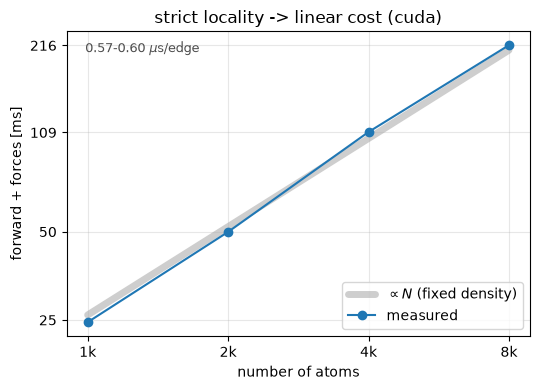

In [21]:
# Plot the timing results on a log-log scale, comparing the measured times to
# the ideal linear scaling with respect to the number of atoms (N)
fig, ax = plt.subplots(figsize=(5.5, 4))

# Draw the ideal as a wide band so the measurement is visible riding on top of
# it
per_atom = np.median(np.array(times) / np.array(Ns))
ax.loglog(Ns, np.array(Ns) * per_atom, color="0.65", lw=5, alpha=0.55,
          solid_capstyle="round", zorder=1, label=r"$\propto N$ (fixed density)")
ax.loglog(Ns, times, "o-", color="C0", lw=1.5, ms=6, zorder=2, label="measured")
us_per_edge = [1e3 * t / e for t, e in zip(times, edges)]
ax.text(0.04, 0.93, f"{min(us_per_edge):.2f}-{max(us_per_edge):.2f} " + r"$\mu$s/edge",
        transform=ax.transAxes, fontsize=9, color="0.3")
ax.set_xticks(Ns); ax.set_xticklabels([f"{n // 1024}k" for n in Ns])
ax.set_yticks([round(t) for t in times])
ax.set_yticklabels([f"{t:.0f}" for t in times])
ax.minorticks_off()
ax.set_xlabel("number of atoms")
ax.set_ylabel("forward + forces [ms]")
ax.set_title(f"strict locality -> linear cost ({device})")
ax.legend(loc="lower right")
ax.grid(alpha=0.3, which="both")
fig.tight_layout()

So, why we chose this range for the number of atoms in our experiment? Each call
dispatches $\approx 1700$ CUDA kernels at $N = 1024$ which is set by the model's
compute graph (e3nn splits every tensor product and linear operation into many
tiny per-path kernels. The backward pass adds $\approx 2.5\times$ the forward's
$\approx 500$). Below $\approx 35000$ edges, a fixed $\approx 20$ ms of launch
overhead swamps the arithmetic intensity. Therefore, we chose to start the sweep
at $N = 1024$ to ensure that the system size is right past the kernel launch
overhead crossover. 

On CPU, the dispatch-overhead floor is higher ($\approx 40$ ms), but the
per-edge cost is $\approx 13\times$ that of the GPU. Therefore, the compute work
wins over the dispatch-overhead ay system sizes with $\approx 6\times$ fewer
atoms. As such, we run the cell sweeps between 256 and 2048 atoms. 

Fusing those launches is what cuEquivariance does in Lessons 12a and 12b. The
cost ceiling there is the **model's per-edge memory** ($\approx 3.6$ GiB at $N =
8192$), not our $\mathcal{O}(N^2)$ neighbour search, whose distance matrix
requires only 0.25 GiB in memory.

Considering the details above, you should read the figure for its slope, not the
intercept: the absolute per-edge cost is hardware- and load-dependent (a factor
of two on a busy GPU), while its constancy across $N$ is what we are focusing
on.

## Summary

In this lesson, we have learned:

- We implemented Allegro's full pipeline using the two-body embeddings with
  species one-hot encodings, $N_\text{layer}$ two-route (scalar and tensor)
  latent space layers, pairwise readout and aggregation, and atomic forces via autograd.
- We verified the energy invariance and force covariance under random rotations,
  inversion, and translations of the input systems at $\sim 10^{-15}$ error
  threshold. The trained float32 model has an energy error at its round-off
  floor ($\sim 10^{-6}$ eV).
- The envelope function, $u(r)$, used on every pair quantity makes the potential
  smooth at the cutoff. We have verified this property using a batched pair
  scan, where beyond the cutoff radius, $r_c$, the energy is exactly equal to
  twice the isolated-atom shift, $2\mu$, and the forces vanish smoothly.
- We have trained the simplified version of Allegro we implemented on the
  rMD17's aspirin trajectory data under Lesson 08c's protocol: **≈62 meV/Å**
  validation force MAE and ≈1.5 meV/atom, against NequIP's **85.28 meV/Å** and
  1.51 meV/atom on the same 150 frames with 12,171 parameters to NequIP's 70,794
  and ≈200 s to its 473 s. (Note that although we fixed the seed, the GPU
  scatter-adds use nondeterministic atomic kernels. So, the repeated runs land
  within about 1 meV/Å of each other.) Each model is trained under its own
  paper's loss for consistenty. So, you should read the results of this
  experiment as two published recipes on one dataset rather than a
  single-variable ablation.
- The cost of forward pass through the model grows linearly with atom count at a
  fixed density. Our timing experiment offers a small-scale demonstration of
  Allegro's $\mathcal{O}(N)$ scaling, which is a direct consequence of its
  strict locality. 

**Next:** In [Lesson 10](10a_ace_theory.ipynb), we focus on the Atomic Cluster
Expansion, which make the body-order view of the iterated tensor products
we saw in this lesson, explicit.

## Exercises

**1. Ablate the tensor track (Difficulty: 🌶️🌶️):** Build the model with
`l_max=0`, so that $\vec{Y}$ reduces to the constant $Y_{00}$, the tensor track
carries only scalars, and every layer collapses to an MLP of distances. Retrain
it with the optimizer, scheduler and epoch budget of the main text and compare
the validation force MAE against the $\ell_\text{max} = 2$ run. By how much does
it degrade? Lesson 08c's Exercise 1 asked you to predict this gap; explain why
the LJ argon dataset would have hidden it.

<details><summary>Solution</summary>

Rebuild the model, the optimizer and the scheduler, then re-run the training
loop cell with `model0` in place of `model`:

```python
# Set the random seed for reproducibility
torch.manual_seed(0)

# Build the model with l_max=0
model0 = AllegroModel(r_cut=r_cut, n_species=N_SPECIES, avg_n_neighbors=avg_n, l_max=0,
                      energy_shift=0.0, energy_scale=float(F_scale)).to(device)

# Initialize the optimizer and scheduler
opt = torch.optim.Adam(model0.parameters(), lr=1e-2)
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=n_epochs)
# ... re-run the training loop with model0, then evaluate(model0)
```

```
l_max=0: params  8,283 | E MAE 3.66 meV/atom | F MAE 131.3 meV/A
l_max=2: params 12,171 | E MAE 1.51 meV/atom | F MAE  62.4 meV/A
```

Dropping the tensor track costs a factor of about 2.1 on forces and 2.4 on
energies (the GPU scatter-adds are nondeterministic as mentioned in the text.
Thus, expect your numbers to move by a few meV/Å). The $\ell_\text{max} = 2$
model improvement comes with only 1.5 $\times$ the parameters. Note that the
invariant model is not broken: 131 meV/Å is a working potential. It is simply
unable to effectively resolve what the equivariant features can resolve for
free.

With `l_max=0`, the environment embedding $\sum_k w^{ik} Y_{00}$ is a sum of
learned radial functions of $r_{ik}$. So, the latent $x^{ij}$ only ever sees the
interatomic distances. Bond angles, dihedrals and the aromatic ring of aspirin
enter the DFT energy through the **directions** of several neighbours at once,
which is exactly the information the $\ell \ge 1$ products $V^{ij} \otimes
\vec{Y}^{ik}$ correlate in a single layer. A distance-only model has to rebuild
these features indirectly from the overlapping distance patterns, and having
only two layers are not enough to recover them.
</details>

**2. Break the smoothness property at the cutoff (Difficulty: 🌶️🌶️):** Remove
the envelope function, `u(r)`, from the readout line of `AllegroModel.forward`
(so that `E_ij = self.readout(x).squeeze(-1)`). Then, load the trained weights
into the modified model and re-run the C-C pair scan. Does the `beyond cutoff`
check still pass? Then predict what the same model would do inside a
radius-graph neighbour list, where an edge with $r_{ij} \ge r_c$ is dropped
altogether. Why does the trouble sit exactly at $r = r_c$?

<details><summary>Solution</summary>

**No. The beyond cutoff check fails**. The reason is a chain of three small
factors:

1. **The pair latent vanishes at the cutoff.** Everything feeding the readout
   already carries the envelope, $u(r_{ij})$: the two-body embedding and each
   layer's residual update. So, the latent `x` $\to 0$ as $r_{ij} \to r_c$.
2. The `self.readout` is an ordinary MLP **with bias terms**. Thus,
   `self.readout(0)` is some nonzero constant $b$. For the trained weights, $b
   \approx 6.8 \times 10^{-3}$. Multiplying $b$ by the envelope factor was the
   only thing hiding it.
3. **And the constant $b$ (in $E_i$) is scaled into the total energy.** The model
   returns $E_\text{system} = \sum_i \sigma E_i + \mu$, where $\sigma$
   (`model.scale`, $\approx 1.01$ eV after training) is the global energy scale
   and $\mu$ (`model.shift`) the per-atom offset. One stray edge is therefore
   worth $\sigma b \approx 6.9$ meV.

In the notebook's C-C scan, the $r > r_c$ edges are deliberately kept in the
graph. Therefore, nothing disappears from the total energy and the energy curve
stays continuous. However, instead of decaying to zero, the energy curve
flattens onto a plateau at

$$E - 2\mu = 2\sigma b \approx 13.7\ \text{meV}$$

counting two ordered edges per dimer ($ij$ and $ji$). Recall from the example
that the `beyond cutoff` check demanded exactly $|E - 2\mu| = 0$. Hence, the
test fails. The atomic forces remain valid here, regardless: a plateau is
constant and the derivative of a constant is zero. As such, the scan reports
exactly $0$ meV/Å for forces beyond $r_c$.

**Regarding the radius-graph neighbour list part of the question:** While both
training and MD actually use the edges, they are deleted wherever $r_{ij} \ge
r_c$. In this case, the energy genuinely jumps by $2\sigma b$ at the cutoff, and
the force, being its derivative, spikes. Every pair term, crossing $r_c$, kicks
the system, and MD stops conserving the energy (Lesson 05b).

**Why exactly at $r_c$?** Because $u$ is the only mechanism that drives a pair's
contribution to zero at the cutoff radius, and with it removed from the readout,
the readout is the one pair quantity left that fails to vanish there. This is
why every pair quantity in Allegro carries the envelope.
</details>

**3. Body order (Difficulty: 🌶️🌶️🌶️):** *Body order* is the number of atoms a
feature correlates at once: a pair distance is 2-body, a bond angle 3-body. Our
model is built with `n_layers=2`. The paper expands the tensor-track feature
after $L$ layers, $V^{ij,L}$, into iterated tensor products $\vec{Y}^{ij}
\otimes \vec{Y}^{ik_1} \otimes \cdots \otimes \vec{Y}^{ik_L}$. What body order
does our $V^{ij,2}$ reach? In what sense is that "analogous but not equivalent"
to the atomic cluster expansion (ACE, Lesson 10a)? And is our body order
actually finite?

<details><summary>Solution</summary>

**Unroll the recursion.** Write $\mathcal{E}_i^{L} = \sum_{k \in \mathcal{N}(i)}
w^{ik,L}\,\vec{Y}^{ik}$ for the embedded environment that layer $L$ builds using
the scatter-add in `AllegroLayer.forward`. The tensor latent route starts as one
pair direction and picks up exactly one environment factor per layer:

| after | feature | atoms involved | body order |
|---|---|---|---|
| 0 layers | $V^{ij,0} \sim \vec{Y}^{ij}$ | $i,\ j$ | 2 |
| 1 layer | $V^{ij,1} \sim \vec{Y}^{ij} \otimes \mathcal{E}_i^{1}$ | $i,\ j,\ k_1$ | 3 |
| 2 layers | $V^{ij,2} \sim \vec{Y}^{ij} \otimes \mathcal{E}_i^{1} \otimes \mathcal{E}_i^{2}$ | $i,\ j,\ k_1,\ k_2$ | 4 |

Every environment factor adds one new neighbour index, so **body order =
`n_layers` + 2**, and our model is 4-body. The $+2$ is the centre $i$ and its
pair partner $j$, which are present before any layer runs.

**Why this picture is analogous to that of ACE, but not equivalent to it?** ACE
builds a $\nu$-body basis from the same ingredients: a product of spherical
harmonics summed over neighbours, in which $\nu$ counts the correlated
neighbours. Therefore, ACE's body order is $\nu + 1$ with the centre included.
Matching $\nu + 1 = $ `n_layers` $+\,2$ gives $\nu = 3$ for our 2-layer model
based on the same core iterated tensor products. It is important to note that
two things are still different:

- ACE weights each spherical harmonic function, $\vec{Y}^{ik}$, by a fixed
  two-body radial-chemical function $R_n(r_{ik}, z_k)$. Allegro's $w^{ik,L}$,
  however, are **learned from the scalar latents of all lower layers**. Thus,
  how much a higher-order term matters is itself a learned function of the
  lower-order picture of the environment.
- ACE carries a full index set $n_1 \dots n_\nu$ that grows at every order,
  while Allegro mixes channels with a learned `o3.Linear` and holds the layer
  width fixed.

**Is our Allegro's body order finite?** No. The table counts only the tensor
products, but `latent_mlp` applies a SiLU after the environment sum has entered
the scalar track. Also, a nonlinear function of a sum over neighbours expands
into products of arbitrarily many neighbour terms. So, the formal body order is
unbounded. The SiLU inside `two_body_mlp` is harmless by contrast: it acts on
one pair at a time, before any neighbour sum, which makes it the analogue of a
nonlinear radial basis in ACE rather than a body-order-raising term.
</details>


## References

- [Musaelian et al., *Learning local equivariant representations for large-scale atomistic dynamics* Nat. Commun. 14 579 (2023)](https://doi.org/10.1038/s41467-023-36329-y)